# Avance 2 · Proyecto de aula de Minería de Datos
## Clasificación del nivel de riesgo en un conjunto de datos sintético de salud: EDA, entrenamiento y evaluación de modelos

**Integrantes:** Roberto Andrés Cortes Castillejo · Roiner Luis Mejía Arrieta · Santiago De Jesús Remolina López
**Universidad:** Universidad de la Costa (Barranquilla, Colombia) · **Asignatura:** Minería de Datos · **Docente:** José Escorcia Gutierrez


# 0. Presentación del proyecto y continuidad con el primer avance

| Elemento | Descripción |
|---|---|
| **Tipo de proyecto** | **Clasificación supervisada multiclase** |
| **Pregunta de investigación** | ¿Es posible predecir el nivel de riesgo (`Nivel_Riesgo`: Bajo, Medio, Alto) a partir de características demográficas, clínicas simuladas y de hábitos, y qué modelo (regresión logística o árbol de decisión) lo hace de forma más adecuada, prestando especial atención a los errores sobre la clase Alto? |
| **Objetivo general** | Aplicar un proceso reproducible de EDA, entrenamiento y evaluación para comparar una regresión logística y un árbol de decisión sobre `Nivel_Riesgo`. |
| **Variable objetivo** | `Nivel_Riesgo` (categórica ordinal: Bajo, Medio, Alto). |
| **Dataset** | `Dataset_Sintetico_Salud_EDA.xlsx`, hoja `Datos` (más las hojas `Diccionario` y `Ficha_tecnica`). 500 registros y 14 columnas, periodo enero–diciembre de 2025. |
| **Fuente** | Según su ficha técnica, son datos generados de forma sintética con semilla fija, con propósito docente (práctica de EDA). **Enlace de descarga: pendiente de confirmar por el grupo** (el archivo no documenta una URL; se recibió como recurso de la asignatura). |
| **Relación con el primer avance** | Se conserva el mismo dataset, la misma limpieza (eliminar 3 duplicados exactos), el mismo diseño de pipelines, la misma partición (75 %/25 %, estratificada, semilla 42) y los mismos dos clasificadores, y se verifica en la sección 5 que los resultados se reproducen. |

### Cambios frente al primer avance (declarados y justificados)

1. **Enfoque único de clasificación.** El primer avance incluía regresión lineal (estimar glucosa), clasificación y K-means. La guía del segundo avance pide una tarea coherente con la pregunta. La pregunta con mayor sentido es la clasificación de `Nivel_Riesgo`: la regresión lineal obtuvo R² = 0.17 (modelo base débil) y K-means una silueta de 0.182 (estructura débil), y ninguno responde a la pregunta de riesgo. Ambos quedan **documentados como antecedente en el informe del primer avance**, no como parte de este avance.
2. **EDA completo y orientado a la pregunta** (el primer avance modelaba directamente).
3. **Elección de la profundidad del árbol.** En el primer avance se eligió mirando el accuracy en prueba, lo que contamina ligeramente ese conjunto. Aquí se usa **solo validación cruzada sobre el entrenamiento** para justificar la configuración y el conjunto de prueba se reserva para la evaluación final.
4. **Evaluación ampliada:** métricas por clase, validación cruzada, comparación entrenamiento vs. prueba y análisis específico de los errores de la clase Alto.

# 1. Preparación del entorno

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, make_scorer, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
import sklearn

warnings.filterwarnings("ignore")
SEMILLA = 42
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titlesize": 13, "axes.labelsize": 11})
pd.set_option("display.width", 200)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


## 1.1 Carga del dataset


In [2]:
RUTA = Path("Dataset_Sintetico_Salud_EDA.xlsx")
if not RUTA.exists():
    raise FileNotFoundError("Coloque Dataset_Sintetico_Salud_EDA.xlsx junto al notebook.")

df_original = pd.read_excel(RUTA, sheet_name="Datos")
df_original["Mes_Registro"] = pd.to_datetime(df_original["Mes_Registro"])
diccionario = pd.read_excel(RUTA, sheet_name="Diccionario")

print(f"Dimensiones originales: {df_original.shape[0]} filas y {df_original.shape[1]} columnas")
diccionario

Dimensiones originales: 500 filas y 14 columnas


,Variable,Tipo,Unidad / valores,Descripción
0,ID_Paciente,Identificador,Texto,Código sintético del paciente. No contiene inf...
1,Mes_Registro,Temporal,Mes de 2025,Mes en que se registró la observación.
2,Edad,Numérica discreta,Años,Edad de la persona al momento del registro.
3,Genero,Categórica nominal,"Femenino, Masculino, Otro/No reporta",Categoría de género simulada.
4,IMC,Numérica continua,kg/m²,Índice de masa corporal simulado.
5,Glucosa_mg_dL,Numérica continua,mg/dL,Medición simulada de glucosa.
6,Presion_Sistolica_mmHg,Numérica continua,mmHg,Medición simulada de presión arterial sistólica.
7,Colesterol_mg_dL,Numérica continua,mg/dL,Medición simulada de colesterol total.
8,Actividad_Fisica,Categórica ordinal,"Baja, Moderada, Alta",Nivel general de actividad física simulado.
9,Fumador,Categórica binaria,"Sí, No",Indica consumo de tabaco en el escenario simul...


# 2. Preparación de los datos

## 2.1 Revisión de calidad: tipos, faltantes, duplicados y categorías

In [3]:
calidad = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "nulos": df_original.isna().sum(),
    "% nulos": (df_original.isna().mean() * 100).round(2),
    "únicos": df_original.nunique(dropna=True),
})
print("Duplicados exactos (fila completa):", df_original.duplicated().sum())
print("ID_Paciente únicos:", df_original["ID_Paciente"].nunique(), "de", len(df_original))
print("Total de celdas nulas:", int(df_original.isna().sum().sum()))
calidad

Duplicados exactos (fila completa): 3
ID_Paciente únicos: 497 de 500
Total de celdas nulas: 25


,tipo,nulos,% nulos,únicos
ID_Paciente,object,0,0.0,497
Mes_Registro,datetime64[ns],0,0.0,12
Edad,int64,0,0.0,65
Genero,object,0,0.0,3
IMC,float64,5,1.0,168
Glucosa_mg_dL,float64,6,1.2,82
Presion_Sistolica_mmHg,int64,0,0.0,66
Colesterol_mg_dL,float64,3,0.6,124
Actividad_Fisica,object,4,0.8,3
Fumador,object,0,0.0,2


In [4]:
# Consistencia de categorías: valores únicos y espacios o mayúsculas inconsistentes
for col in ["Genero", "Actividad_Fisica", "Fumador", "Nivel_Riesgo"]:
    valores = df_original[col].dropna()
    inconsistentes = (valores != valores.str.strip()).sum()
    print(f"{col:17s} -> {sorted(valores.unique())} | con espacios sobrantes: {inconsistentes}")
print()
print("Registros duplicados detectados:")
df_original[df_original.duplicated(keep=False)].sort_values("ID_Paciente")

Genero            -> ['Femenino', 'Masculino', 'Otro/No reporta'] | con espacios sobrantes: 0
Actividad_Fisica  -> ['Alta', 'Baja', 'Moderada'] | con espacios sobrantes: 0
Fumador           -> ['No', 'Sí'] | con espacios sobrantes: 0
Nivel_Riesgo      -> ['Alto', 'Bajo', 'Medio'] | con espacios sobrantes: 0

Registros duplicados detectados:


,ID_Paciente,Mes_Registro,Edad,Genero,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Actividad_Fisica,Fumador,Horas_Sueno,Nivel_Estres,Consultas_Medicas,Nivel_Riesgo
8,PAC-0009,2025-08-01,65,Femenino,32.2,113.0,150,237.0,Baja,No,8.4,4,3,Alto
497,PAC-0009,2025-08-01,65,Femenino,32.2,113.0,150,237.0,Baja,No,8.4,4,3,Alto
176,PAC-0177,2025-04-01,61,Femenino,26.8,106.0,118,214.0,Baja,No,6.4,4,2,Alto
498,PAC-0177,2025-04-01,61,Femenino,26.8,106.0,118,214.0,Baja,No,6.4,4,2,Alto
392,PAC-0393,2025-12-01,30,Masculino,19.3,84.0,128,178.0,Alta,Sí,5.2,5,3,Bajo
499,PAC-0393,2025-12-01,30,Masculino,19.3,84.0,128,178.0,Alta,Sí,5.2,5,3,Bajo


**Hallazgos de calidad.** Hay 3 filas duplicadas exactas (coinciden con los 3 identificadores repetidos: 497 pacientes únicos) y 25 celdas nulas repartidas en cinco variables (IMC, glucosa, colesterol, actividad física y horas de sueño). Las categorías no presentan inconsistencias de escritura.

## 2.2 Decisiones de preparación y su justificación

| Decisión | Justificación técnica |
|---|---|
| Eliminar los 3 duplicados exactos **antes** de dividir | Una copia en entrenamiento y otra en prueba inflaría las métricas (fuga de información). |
| **No** eliminar filas con nulos; imputar dentro del pipeline | Son pocos (≤ 1.4 % por variable). Imputar dentro del pipeline hace que la mediana o la moda se aprendan **solo con el entrenamiento**. |
| Excluir `ID_Paciente` | Identificador único sin información clínica; permitiría memorizar registros. |
| Derivar `Mes_Numero` (1–12) a partir de `Mes_Registro` | Un `datetime` no es utilizable directamente. Se conserva por continuidad con el primer avance; el EDA evaluará si aporta información. |
| Conservar los valores atípicos | Son plausibles clínicamente (p. ej. glucosa de 336 mg/dL) y la ficha técnica indica que fueron incluidos de forma intencional. Se evalúa su efecto sobre los modelos. |
| Numéricas: mediana + estandarización | La mediana es robusta a atípicos; la estandarización es necesaria para la regresión logística (regularización y comparabilidad de coeficientes). No es necesaria para el árbol, pero no lo perjudica. |
| Categóricas: moda + one-hot | Variables nominales/ordinales de pocas categorías. |
| `Nivel_Riesgo` **no** entra como predictor (es el objetivo) | Evidente, pero se verifica en la sección 4. |

**Posible fuga de información (a tener presente).** La ficha técnica indica que `Nivel_Riesgo` fue *construida a partir de varias características*. Por tanto, parte del rendimiento de los modelos refleja la recuperación de una regla de construcción sintética, y no necesariamente un fenómeno real. Esto limita cualquier generalización.

In [5]:
df = df_original.drop_duplicates().copy()
df["Mes_Numero"] = df["Mes_Registro"].dt.month

# Versión final de los datos usada para el EDA y el modelado
print(f"Registros: {len(df_original)} -> {len(df)} (se eliminaron {len(df_original) - len(df)} duplicados)")
print(f"Columnas: {df_original.shape[1]} originales + 1 derivada (Mes_Numero) = {df.shape[1]}")

ORDEN = ["Bajo", "Medio", "Alto"]
NUMERICAS = ["Edad", "IMC", "Glucosa_mg_dL", "Presion_Sistolica_mmHg", "Colesterol_mg_dL",
             "Horas_Sueno", "Nivel_Estres", "Consultas_Medicas", "Mes_Numero"]
CATEGORICAS = ["Genero", "Actividad_Fisica", "Fumador"]
OBJETIVO = "Nivel_Riesgo"
PREDICTORES = NUMERICAS + CATEGORICAS
assert OBJETIVO not in PREDICTORES and "ID_Paciente" not in PREDICTORES
assert all(c in df.columns for c in PREDICTORES + [OBJETIVO])
print("Predictores:", len(PREDICTORES), "(", len(NUMERICAS), "numéricos +", len(CATEGORICAS), "categóricos )")

Registros: 500 -> 497 (se eliminaron 3 duplicados)
Columnas: 14 originales + 1 derivada (Mes_Numero) = 15
Predictores: 12 ( 9 numéricos + 3 categóricos )


## 2.3 Valores atípicos (criterio IQR: 1.5 × rango intercuartílico)
La tabla cuantifica los registros fuera de los límites; la decisión (conservarlos) se justificó arriba y se discute con el diagrama de cajas de la sección 3.

In [6]:
filas = []
for c in NUMERICAS:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m = (df[c] < lo) | (df[c] > hi)
    filas.append({"variable": c, "límite inf.": round(lo, 1), "límite sup.": round(hi, 1),
                  "n atípicos": int(m.sum()), "% atípicos": round(100 * m.mean(), 2),
                  "mín. atípico": df.loc[m, c].min() if m.any() else np.nan,
                  "máx. atípico": df.loc[m, c].max() if m.any() else np.nan})
tabla_atipicos = pd.DataFrame(filas).set_index("variable")
tabla_atipicos

,límite inf.,límite sup.,n atípicos,% atípicos,mín. atípico,máx. atípico
variable,,,,,,
Edad,5.5,89.5,0,0.00,NaN,NaN
IMC,14.9,39.4,4,0.80,42.1,58.2
Glucosa_mg_dL,60.8,146.8,7,1.41,150.0,336.0
Presion_Sistolica_mmHg,87.0,159.0,6,1.21,85.0,226.0
Colesterol_mg_dL,98.5,278.5,0,0.00,NaN,NaN
Horas_Sueno,4.6,9.4,9,1.81,3.8,9.8
Nivel_Estres,-0.5,11.5,0,0.00,NaN,NaN
Consultas_Medicas,-3.5,8.5,1,0.20,9.0,9.0
Mes_Numero,-6.0,18.0,0,0.00,NaN,NaN


# 3. Análisis Exploratorio de Datos (EDA) orientado a la pregunta

El EDA se hace sobre los 497 registros sin duplicados. Es **descriptivo**: no ajusta transformaciones que alimenten a los modelos (esas se aprenden después, solo con el entrenamiento, dentro de pipelines).

## 3.1 Estadísticas descriptivas

In [7]:
desc = df[NUMERICAS].describe().T.round(2)
desc["asimetría"] = df[NUMERICAS].skew().round(2)
desc

,count,mean,std,min,25%,50%,75%,max,asimetría
Edad,497.0,47.59,15.18,18.0,37.00,47.00,58.0,85.0,0.18
IMC,492.0,27.22,4.80,17.0,24.08,26.85,30.2,58.2,1.25
Glucosa_mg_dL,491.0,104.74,24.61,62.0,93.00,103.00,114.5,336.0,4.60
Presion_Sistolica_mmHg,497.0,123.28,14.69,85.0,114.00,122.00,132.0,226.0,1.53
Colesterol_mg_dL,494.0,189.03,29.81,115.0,166.00,189.50,211.0,266.0,0.03
Horas_Sueno,490.0,7.00,0.96,3.8,6.40,7.10,7.6,9.8,-0.21
Nivel_Estres,497.0,5.58,2.03,1.0,4.00,5.00,7.0,10.0,0.14
Consultas_Medicas,497.0,2.64,1.70,0.0,1.00,3.00,4.0,9.0,0.39
Mes_Numero,497.0,6.34,3.47,1.0,3.00,6.00,9.0,12.0,0.03


## 3.2 Distribución de la variable objetivo y desbalance de clases

,registros,% del total
Nivel_Riesgo,,
Bajo,169,34.0
Medio,196,39.4
Alto,132,26.6


Razón clase mayoritaria / minoritaria: 1.48


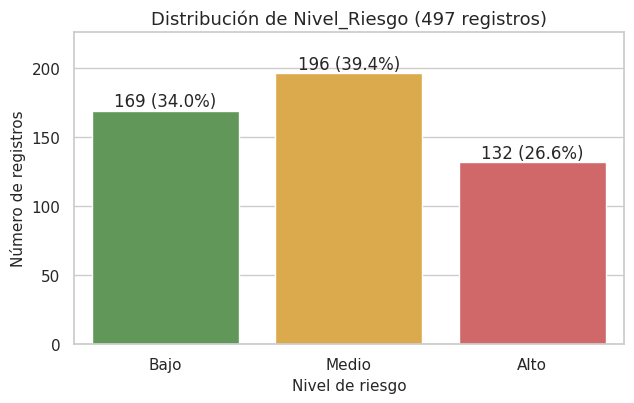

In [8]:
conteo = df[OBJETIVO].value_counts().reindex(ORDEN)
prop = (conteo / conteo.sum() * 100).round(1)
display(pd.DataFrame({"registros": conteo, "% del total": prop}))
print(f"Razón clase mayoritaria / minoritaria: {conteo.max() / conteo.min():.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.barplot(x=conteo.index, y=conteo.values, order=ORDEN, palette=["#59A14F", "#F2B134", "#E15759"], ax=ax)
for i, v in enumerate(conteo.values):
    ax.text(i, v + 3, f"{v} ({prop.iloc[i]}%)", ha="center")
ax.set(title="Distribución de Nivel_Riesgo (497 registros)", xlabel="Nivel de riesgo", ylabel="Número de registros", ylim=(0, conteo.max() + 30))
plt.tight_layout(); plt.show()

**Qué representa:** el número de registros por nivel de riesgo. **Interpretación:** las clases están moderadamente desbalanceadas (la clase Medio es la mayoritaria y Alto la minoritaria, con una razón de aproximadamente 1.5 a 1). No es un desbalance severo, pero Alto es justamente la clase de mayor interés, por lo que se usarán pesos de clase balanceados, partición estratificada y métricas por clase (no solo accuracy).

## 3.3 Distribución de las variables numéricas

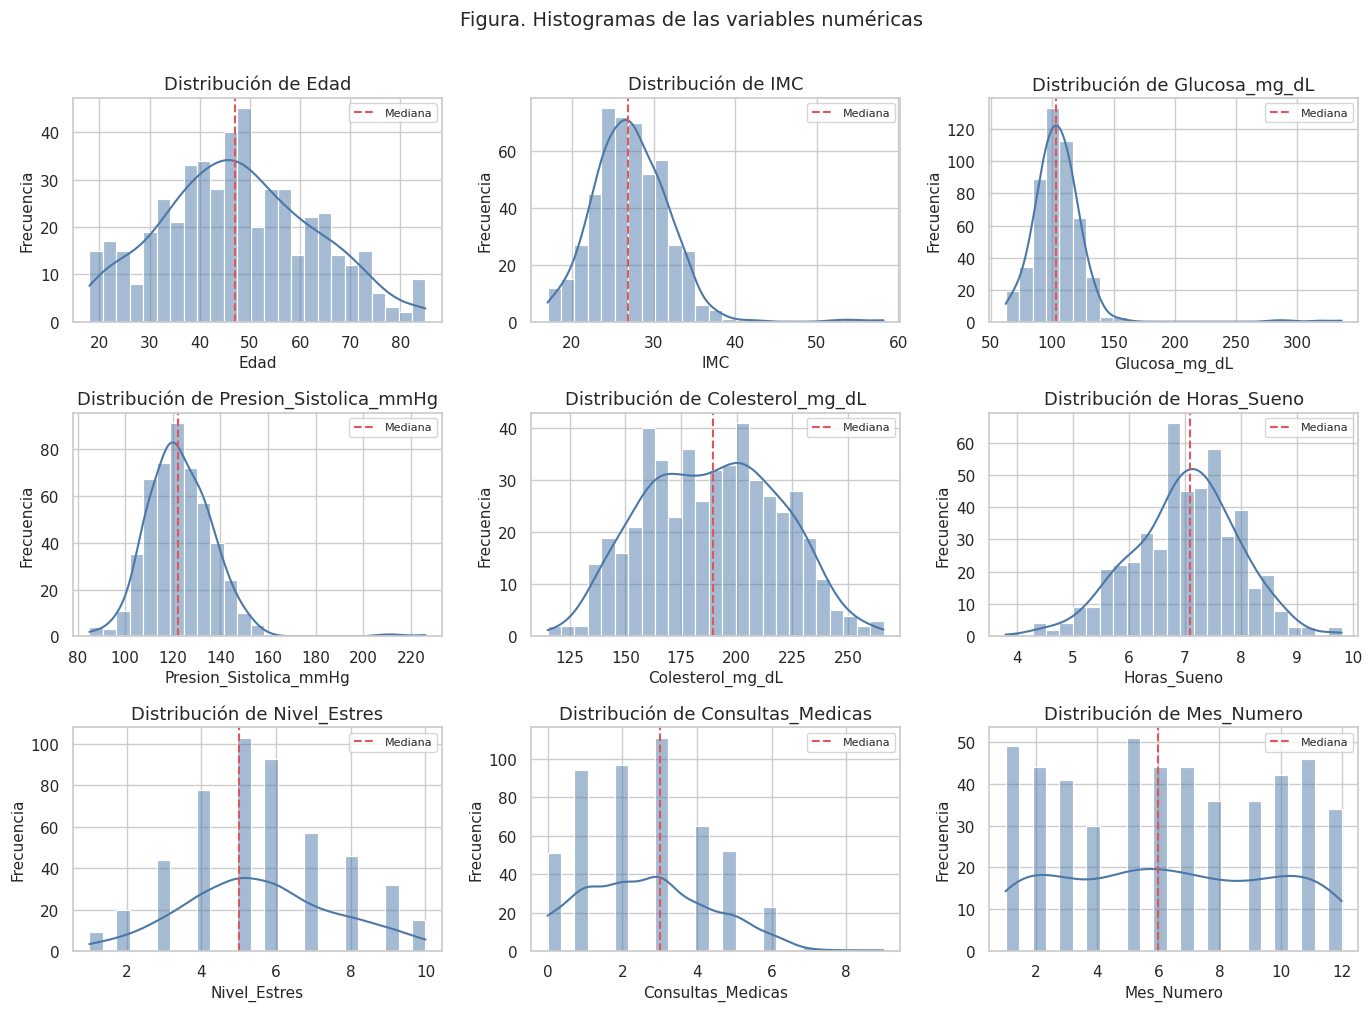

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), NUMERICAS):
    sns.histplot(df[c], kde=True, bins=25, ax=ax, color="#4C78A8")
    ax.axvline(df[c].median(), color="#E15759", ls="--", label="Mediana")
    ax.set(title=f"Distribución de {c}", xlabel=c, ylabel="Frecuencia"); ax.legend(fontsize=8)
fig.suptitle("Figura. Histogramas de las variables numéricas", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

**Qué representa:** la forma de cada variable numérica con su mediana. **Interpretación:** la mayoría de las variables clínicas se distribuyen de forma aproximadamente simétrica. La glucosa (asimetría 4.60), la presión sistólica (1.53) y el IMC (1.25) presentan cola derecha por unos pocos valores muy altos (glucosa hasta 336 mg/dL; IMC hasta 58.2 kg/m²; presión hasta 226 mmHg), coherente con los atípicos de la sección 2.3. Esto respalda usar la mediana para imputar y explica por qué la regresión logística puede ser sensible a esos extremos.

## 3.4 Diagramas de caja de las variables clínicas según el nivel de riesgo (valores atípicos y comparación entre grupos)

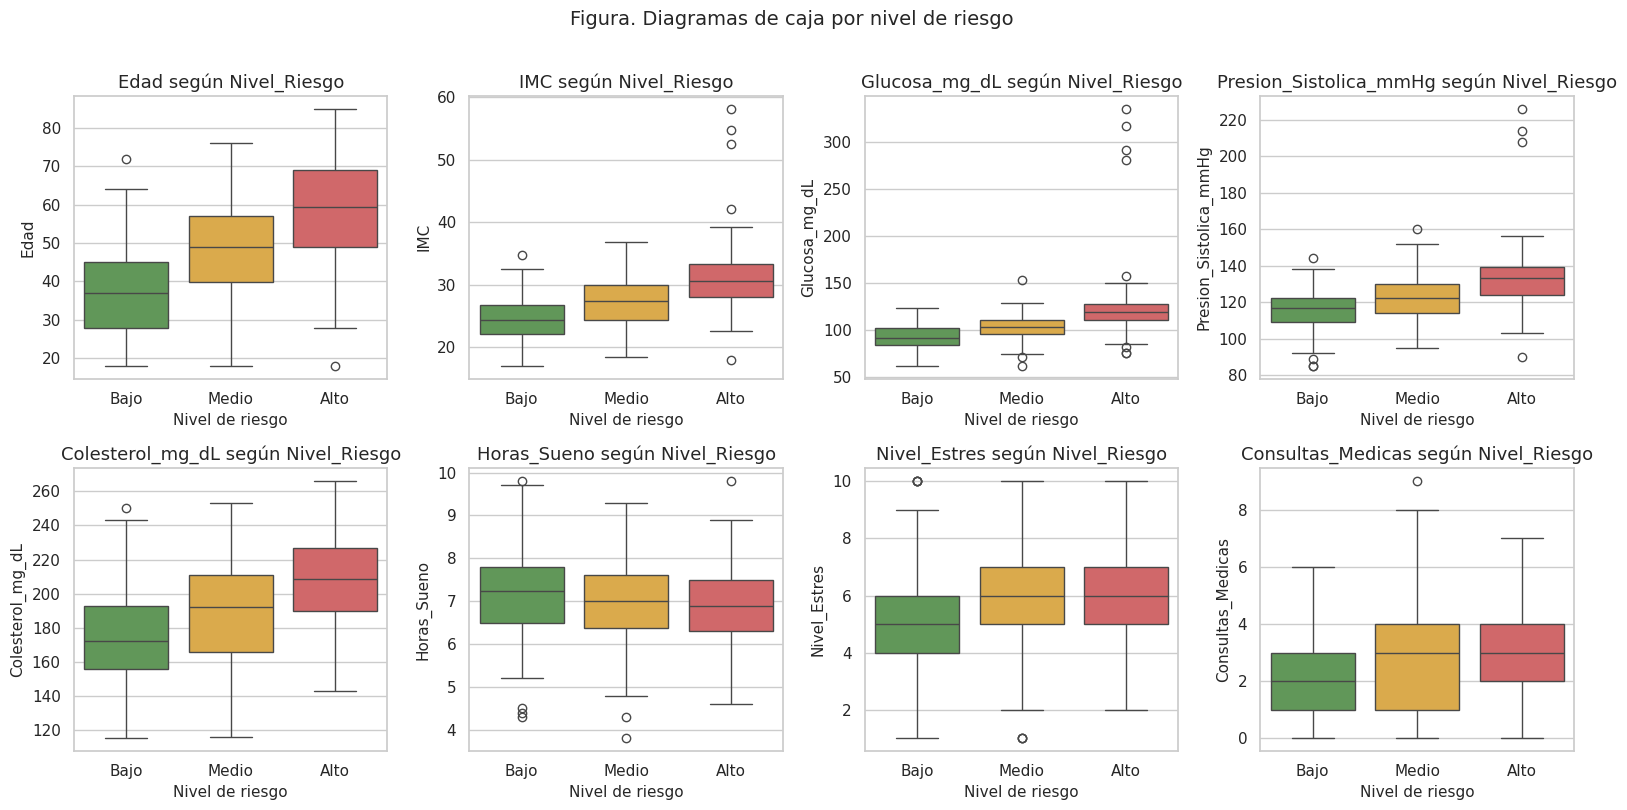

In [10]:
paleta = {"Bajo": "#59A14F", "Medio": "#F2B134", "Alto": "#E15759"}
vars_caja = ["Edad", "IMC", "Glucosa_mg_dL", "Presion_Sistolica_mmHg", "Colesterol_mg_dL", "Horas_Sueno", "Nivel_Estres", "Consultas_Medicas"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, c in zip(axes.ravel(), vars_caja):
    sns.boxplot(data=df, x=OBJETIVO, y=c, order=ORDEN, palette=paleta, ax=ax)
    ax.set(title=f"{c} según Nivel_Riesgo", xlabel="Nivel de riesgo", ylabel=c)
fig.suptitle("Figura. Diagramas de caja por nivel de riesgo", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

In [11]:
# Medianas por grupo y prueba de Kruskal-Wallis (no paramétrica, no asume normalidad)
res = []
for c in NUMERICAS:
    grupos = [df.loc[df[OBJETIVO] == n, c].dropna() for n in ORDEN]
    h, p = stats.kruskal(*grupos)
    res.append({"variable": c, **{f"mediana {n}": df.loc[df[OBJETIVO] == n, c].median() for n in ORDEN},
                "H (Kruskal)": round(h, 1), "p-valor": f"{p:.2e}"})
comparacion_num = pd.DataFrame(res).set_index("variable")
comparacion_num

,mediana Bajo,mediana Medio,mediana Alto,H (Kruskal),p-valor
variable,,,,,
Edad,37.00,49.0,59.5,164.3,2.09e-36
IMC,24.30,27.4,30.6,148.5,5.70e-33
Glucosa_mg_dL,92.00,103.0,119.0,183.0,1.87e-40
Presion_Sistolica_mmHg,117.00,122.0,133.0,118.4,1.98e-26
Colesterol_mg_dL,172.00,192.0,208.5,92.4,8.47e-21
Horas_Sueno,7.25,7.0,6.9,9.0,1.08e-02
Nivel_Estres,5.00,6.0,6.0,18.8,8.24e-05
Consultas_Medicas,2.00,3.0,3.0,23.7,7.28e-06
Mes_Numero,6.00,7.0,6.5,5.8,5.55e-02


**Qué representa:** la distribución de cada variable en cada nivel de riesgo (la caja es el rango intercuartílico; los puntos son atípicos) y una prueba de Kruskal-Wallis. **Interpretación:** Edad, IMC, glucosa, presión sistólica y colesterol aumentan de forma clara y ordenada de Bajo a Medio a Alto, con diferencias estadísticamente muy significativas. Por ejemplo, la mediana de glucosa pasa de 92 mg/dL (Bajo) a 103 (Medio) y 119 (Alto), y la de edad de 37 a 49 y 59.5 años. Estrés (H = 18.8) y consultas médicas (H = 23.7) muestran diferencias mucho menores, y las horas de sueño tienen una diferencia pequeña (mediana de 7.25 a 6.9 h; p = 0.011). El mes de registro no es significativo al 5 % (p = 0.055). Los valores atípicos extremos de glucosa e IMC pertenecen casi todos a la clase Alto (6 de 7 y 4 de 4 en el dataset sin duplicados), de modo que eliminarlos quitaría justamente información de la clase de interés. Son **asociaciones, no causalidad**, y son esperables porque el dataset es sintético y la etiqueta se construyó a partir de estas variables.

## 3.5 Variables categóricas frente al nivel de riesgo

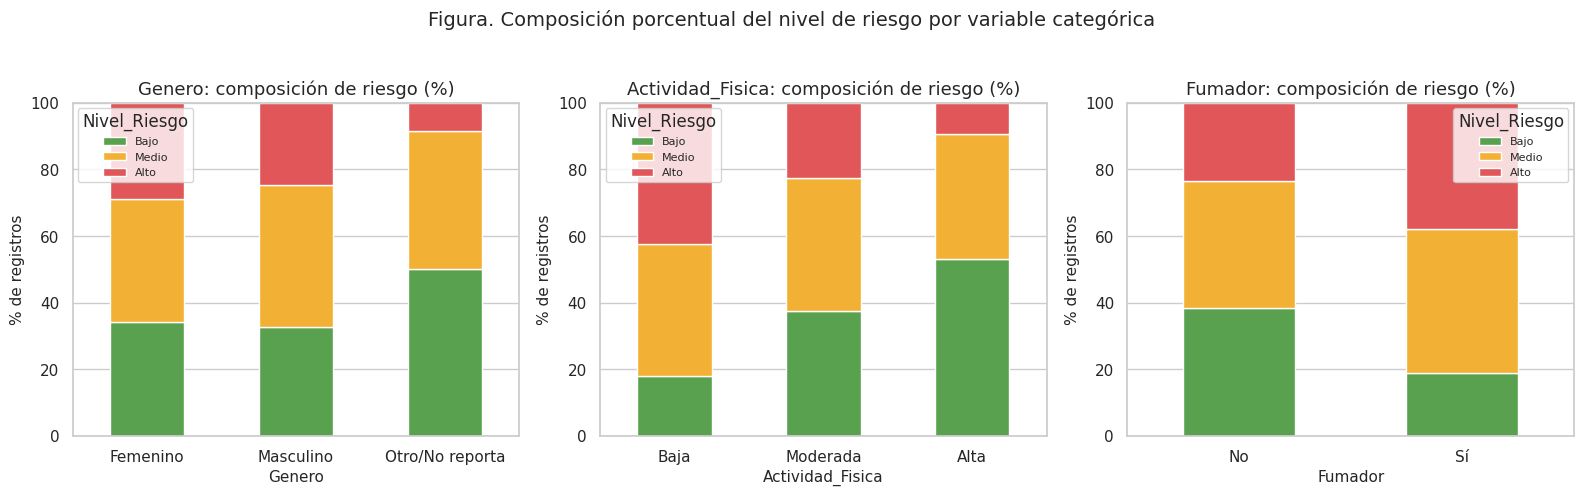

,chi2,p-valor,n mínimo por categoría
variable,,,
Genero,4.5,3.41e-01,12
Actividad_Fisica,55.0,3.19e-11,107
Fumador,16.9,2.10e-04,111


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
orden_cat = {"Genero": ["Femenino", "Masculino", "Otro/No reporta"], "Actividad_Fisica": ["Baja", "Moderada", "Alta"], "Fumador": ["No", "Sí"]}
res_cat = []
for ax, c in zip(axes, CATEGORICAS):
    ct = pd.crosstab(df[c], df[OBJETIVO]).reindex(orden_cat[c])[ORDEN]
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    pct.plot(kind="bar", stacked=True, color=[paleta[n] for n in ORDEN], ax=ax, rot=0)
    ax.set(title=f"{c}: composición de riesgo (%)", xlabel=c, ylabel="% de registros", ylim=(0, 100))
    ax.legend(title="Nivel_Riesgo", fontsize=8)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    res_cat.append({"variable": c, "chi2": round(chi2, 1), "p-valor": f"{p:.2e}", "n mínimo por categoría": int(ct.sum(axis=1).min())})
fig.suptitle("Figura. Composición porcentual del nivel de riesgo por variable categórica", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()
pd.DataFrame(res_cat).set_index("variable")

In [13]:
display(pd.crosstab(df["Actividad_Fisica"], df[OBJETIVO], normalize="index").reindex(["Baja", "Moderada", "Alta"])[ORDEN].mul(100).round(1))
display(pd.crosstab(df["Fumador"], df[OBJETIVO], normalize="index")[ORDEN].mul(100).round(1))

Nivel_Riesgo,Bajo,Medio,Alto
Actividad_Fisica,,,
Baja,18.0,39.5,42.4
Moderada,37.4,40.2,22.4
Alta,53.3,37.4,9.3


Nivel_Riesgo,Bajo,Medio,Alto
Fumador,,,
No,38.3,38.3,23.3
Sí,18.9,43.2,37.8


**Qué representa:** para cada categoría, el porcentaje de registros en cada nivel de riesgo. **Interpretación:** la actividad física y el hábito de fumar se asocian significativamente con el riesgo (chi-cuadrado, p < 0.001): con actividad física baja el 42.4 % de los registros es de riesgo Alto frente al 22.4 % con actividad moderada y el 9.3 % con actividad alta; entre fumadores el 37.8 % es de riesgo Alto frente al 23.3 % de los no fumadores. El género no muestra asociación significativa, y la categoría «Otro/No reporta» tiene solo 12 registros, por lo que cualquier lectura sobre ella es poco fiable. Se mantiene en el modelo por continuidad con el primer avance, pero no se interpreta.

## 3.6 Correlaciones entre variables
Se usa la correlación de **Spearman** (robusta a atípicos y apta para variables ordinales). Para incluir el objetivo se codifica como Bajo = 0, Medio = 1, Alto = 2 **solo para este análisis descriptivo**.

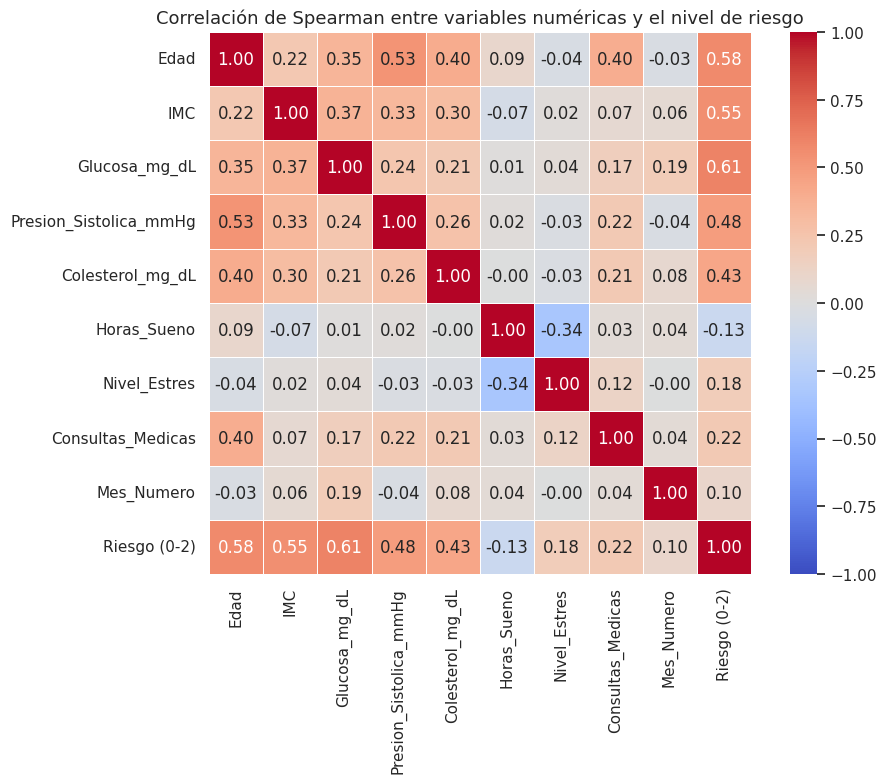

Correlación de Spearman con el nivel de riesgo (ordenada por magnitud):


,Riesgo (0-2)
Glucosa_mg_dL,0.608
Edad,0.575
IMC,0.549
Presion_Sistolica_mmHg,0.484
Colesterol_mg_dL,0.431
Consultas_Medicas,0.218
Nivel_Estres,0.183
Horas_Sueno,-0.135
Mes_Numero,0.100


In [14]:
corr_df = df[NUMERICAS].copy()
corr_df["Riesgo (0-2)"] = df[OBJETIVO].map({"Bajo": 0, "Medio": 1, "Alto": 2})
corr = corr_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax)
ax.set_title("Correlación de Spearman entre variables numéricas y el nivel de riesgo")
plt.tight_layout(); plt.show()

print("Correlación de Spearman con el nivel de riesgo (ordenada por magnitud):")
corr["Riesgo (0-2)"].drop("Riesgo (0-2)").reindex(corr["Riesgo (0-2)"].drop("Riesgo (0-2)").abs().sort_values(ascending=False).index).round(3)

**Qué representa:** la fuerza y el signo de la asociación monótona entre pares de variables. **Interpretación:** las variables más asociadas con el riesgo son glucosa (ρ = 0.61), edad (0.58), IMC (0.55), presión sistólica (0.48) y colesterol (0.43), todas positivas y moderadas, en línea con los diagramas de caja. Consultas médicas (0.22) y estrés (0.18) tienen asociación débil, y horas de sueño (−0.14) y mes (0.10), muy débil. Entre los propios predictores la correlación más alta es la de edad con presión sistólica (0.53), seguida de edad con colesterol (0.40) y edad con consultas (0.40), por lo que no se observa multicolinealidad severa que afecte a la regresión logística.

## 3.7 Relaciones entre variables relevantes

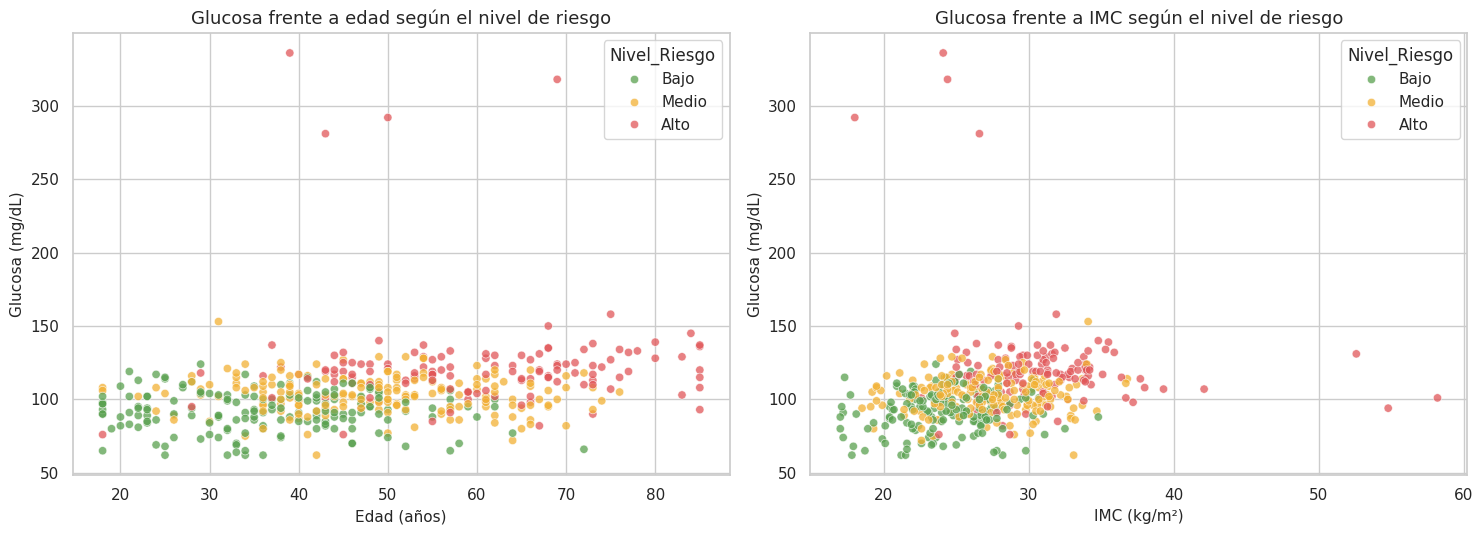

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=df, x="Edad", y="Glucosa_mg_dL", hue=OBJETIVO, hue_order=ORDEN, palette=paleta, alpha=.75, ax=axes[0])
axes[0].set(title="Glucosa frente a edad según el nivel de riesgo", xlabel="Edad (años)", ylabel="Glucosa (mg/dL)")
sns.scatterplot(data=df, x="IMC", y="Glucosa_mg_dL", hue=OBJETIVO, hue_order=ORDEN, palette=paleta, alpha=.75, ax=axes[1])
axes[1].set(title="Glucosa frente a IMC según el nivel de riesgo", xlabel="IMC (kg/m²)", ylabel="Glucosa (mg/dL)")
plt.tight_layout(); plt.show()

**Qué representa:** la posición de cada paciente según dos variables clínicas, coloreada por riesgo. **Interpretación:** el riesgo Alto se agrupa hacia edades mayores, glucosa e IMC más altos, y el riesgo Bajo hacia valores menores, pero **las nubes se solapan**, sobre todo la clase Medio con sus vecinas. Esto anticipa que ningún par de variables separa bien las tres clases por sí solo y que los errores de clasificación se concentrarán en las fronteras Bajo–Medio y Medio–Alto. Los pocos puntos con glucosa muy alta (hasta 336 mg/dL) pertenecen a la clase Alto.

## 3.8 Síntesis del EDA y decisiones de modelado

- La clase objetivo está moderadamente desbalanceada → partición estratificada, `class_weight="balanced"` y métricas por clase.
- Edad, glucosa, IMC, presión y colesterol son los candidatos a ser los predictores más relevantes; sueño y mes aportan poco.
- Las clases se solapan en las fronteras → se espera que los errores ocurran entre clases vecinas.
- Los atípicos se conservan (pertenecen sobre todo a la clase Alto) y se usa imputación por mediana.
- La relación con varias variables parece monótona y aproximadamente lineal en la escala de las variables estandarizadas, lo que hace razonable la regresión logística; el árbol permite además reglas y relaciones no lineales.

# 4. Selección y entrenamiento de los modelos

**Modelos seleccionados y justificación**

- **Regresión logística multinomial:** línea base interpretable para un objetivo de tres clases; sus coeficientes indican la dirección de la asociación y funciona bien cuando las variables se relacionan de forma aproximadamente monótona, como sugiere el EDA.
- **Árbol de decisión:** produce reglas explícitas, captura relaciones no lineales e interacciones sin escalar y complementa a la logística con un enfoque distinto. Es propenso al sobreajuste, por lo que se controla con `max_depth` y `min_samples_leaf`.

No se optimizan hiperparámetros (no es requisito de esta entrega); se conservan los del primer avance y se **justifica** su elección con validación cruzada en entrenamiento.

## 4.1 Separación de predictores y objetivo, y partición entrenamiento/prueba

In [16]:
X = df[PREDICTORES]
y = df[OBJETIVO]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMILLA, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} registros | Prueba: {X_test.shape[0]} registros")
print(pd.DataFrame({"entrenamiento (%)": y_train.value_counts(normalize=True).mul(100).round(1),
                    "prueba (%)": y_test.value_counts(normalize=True).mul(100).round(1)}).loc[ORDEN])

Entrenamiento: 372 registros | Prueba: 125 registros
              entrenamiento (%)  prueba (%)
Nivel_Riesgo                               
Bajo                       33.9        34.4
Medio                      39.5        39.2
Alto                       26.6        26.4


La partición es estratificada: las proporciones de clase son prácticamente iguales en ambos conjuntos. **El conjunto de prueba no se usa para ningún ajuste ni decisión**; solo para la evaluación final.

## 4.2 Pipelines de preparación y modelado
Imputación, escalamiento y codificación se **ajustan únicamente con los datos de entrenamiento** (dentro del pipeline), y se aplican a prueba con los parámetros aprendidos. Dentro de la validación cruzada se reajustan en cada partición, evitando fuga de información.

In [17]:
def crear_preprocesador():
    return ColumnTransformer([
        ("num", Pipeline([("imputacion", SimpleImputer(strategy="median")),
                          ("escalamiento", StandardScaler())]), NUMERICAS),
        ("cat", Pipeline([("imputacion", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAS),
    ])

def crear_logistica():
    return Pipeline([("preprocesamiento", crear_preprocesador()),
                     ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA))])

def crear_arbol(max_depth=5):
    return Pipeline([("preprocesamiento", crear_preprocesador()),
                     ("modelo", DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=8,
                                                       class_weight="balanced", random_state=SEMILLA))])

## 4.3 Justificación de la profundidad del árbol (validación cruzada solo en entrenamiento)
Se compara el F1 macro de entrenamiento y de validación cruzada (5 particiones estratificadas) para distintas profundidades. El conjunto de prueba **no** interviene.

,F1 macro entrenamiento,F1 macro validación (CV),desv. est. CV,brecha
max_depth,,,,
2,0.642,0.583,0.041,0.059
3,0.711,0.594,0.035,0.117
4,0.746,0.617,0.037,0.129
5,0.800,0.615,0.037,0.185
6,0.808,0.630,0.021,0.178
8,0.816,0.632,0.040,0.184
sin límite,0.816,0.632,0.040,0.184


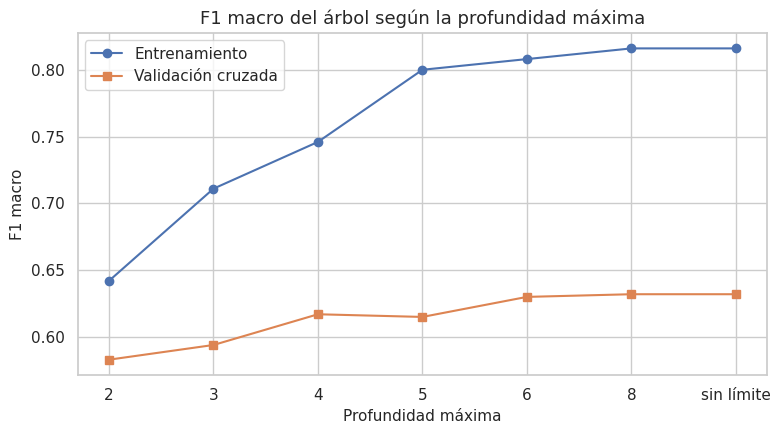

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for prof in [2, 3, 4, 5, 6, 8, None]:
    r = cross_validate(crear_arbol(prof), X_train, y_train, cv=cv, scoring="f1_macro", return_train_score=True)
    filas.append({"max_depth": "sin límite" if prof is None else prof,
                  "F1 macro entrenamiento": r["train_score"].mean(), "F1 macro validación (CV)": r["test_score"].mean(),
                  "desv. est. CV": r["test_score"].std()})
curva_prof = pd.DataFrame(filas).set_index("max_depth").round(3)
curva_prof["brecha"] = (curva_prof["F1 macro entrenamiento"] - curva_prof["F1 macro validación (CV)"]).round(3)
display(curva_prof)

fig, ax = plt.subplots(figsize=(8, 4.5))
x_lab = curva_prof.index.astype(str)
ax.plot(x_lab, curva_prof["F1 macro entrenamiento"], "o-", label="Entrenamiento")
ax.plot(x_lab, curva_prof["F1 macro validación (CV)"], "s-", label="Validación cruzada")
ax.set(title="F1 macro del árbol según la profundidad máxima", xlabel="Profundidad máxima", ylabel="F1 macro"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación:** el F1 macro de entrenamiento sube con la profundidad (de 0.642 a 0.816), mientras que el de validación cruzada se mueve en un rango estrecho (0.583 a 0.632) y la brecha entre ambos aumenta de 0.059 a 0.184, señal típica de sobreajuste. Las profundidades 4 a 8 tienen un F1 de validación parecido (0.615 a 0.632) y sus diferencias son menores que la desviación estándar entre particiones (0.02 a 0.04). Con `max_depth = 5` el F1 de validación es 0.615, algo inferior al de 6 y 8 (0.630 y 0.632), de modo que **5 no es un óptimo estadísticamente demostrado**. Se conserva `max_depth = 5` y `min_samples_leaf = 8` por continuidad con el primer avance, por ser una profundidad moderada que mantiene el árbol legible y porque aumentarla no mejora la validación de forma apreciable. Lo importante es que **ninguna profundidad acerca al árbol al rendimiento de la regresión logística** (F1 macro CV de 0.849, sección 5.4); la diferencia entre modelos no depende de esta elección. Esta justificación usa solo el entrenamiento; el conjunto de prueba no interviene.

## 4.4 Entrenamiento de los modelos

In [19]:
modelo_log = crear_logistica().fit(X_train, y_train)
modelo_arb = crear_arbol(5).fit(X_train, y_train)

pred_log = modelo_log.predict(X_test)
pred_arb = modelo_arb.predict(X_test)
print("Modelos entrenados. Predicciones sobre prueba:", len(pred_log), "registros cada uno.")

Modelos entrenados. Predicciones sobre prueba: 125 registros cada uno.


# 5. Evaluación de los modelos

## 5.1 Métricas globales y por clase

In [20]:
def metricas_globales(y_real, y_pred):
    return {"Accuracy": accuracy_score(y_real, y_pred),
            "Precision macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
            "Recall macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
            "F1 macro": f1_score(y_real, y_pred, average="macro", zero_division=0)}

def reporte_por_clase(y_real, y_pred):
    r = pd.DataFrame(classification_report(y_real, y_pred, labels=ORDEN, output_dict=True, zero_division=0)).T
    return r.loc[ORDEN + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3)

resultados = {"Regresión logística": (pred_log, modelo_log), "Árbol de decisión": (pred_arb, modelo_arb)}
globales = pd.DataFrame({n: metricas_globales(y_test, p) for n, (p, _) in resultados.items()}).T.round(3)
print("MÉTRICAS GLOBALES EN PRUEBA"); display(globales)
for n, (p, _) in resultados.items():
    print(f"\nREPORTE POR CLASE — {n}"); display(reporte_por_clase(y_test, p))

MÉTRICAS GLOBALES EN PRUEBA


,Accuracy,Precision macro,Recall macro,F1 macro
Regresión logística,0.856,0.858,0.862,0.859
Árbol de decisión,0.680,0.708,0.674,0.685



REPORTE POR CLASE — Regresión logística


,precision,recall,f1-score,support
Bajo,0.925,0.860,0.892,43.0
Medio,0.816,0.816,0.816,49.0
Alto,0.833,0.909,0.870,33.0
macro avg,0.858,0.862,0.859,125.0



REPORTE POR CLASE — Árbol de decisión


,precision,recall,f1-score,support
Bajo,0.738,0.721,0.729,43.0
Medio,0.586,0.694,0.636,49.0
Alto,0.800,0.606,0.690,33.0
macro avg,0.708,0.674,0.685,125.0


**Interpretación.** La regresión logística obtiene accuracy 0.856 y F1 macro 0.859; el árbol, 0.680 y 0.685. En ambos modelos la clase Medio es la más difícil (F1 de 0.816 en la logística y 0.636 en el árbol), algo esperable porque es la clase intermedia y se solapa con sus dos vecinas (sección 3.7). La diferencia más relevante está en la clase Alto: la logística detecta al 90.9 % de los registros Alto (recall 0.909) frente al 60.6 % del árbol (0.606), con precisiones similares (0.833 y 0.800).

## 5.2 Matrices de confusión

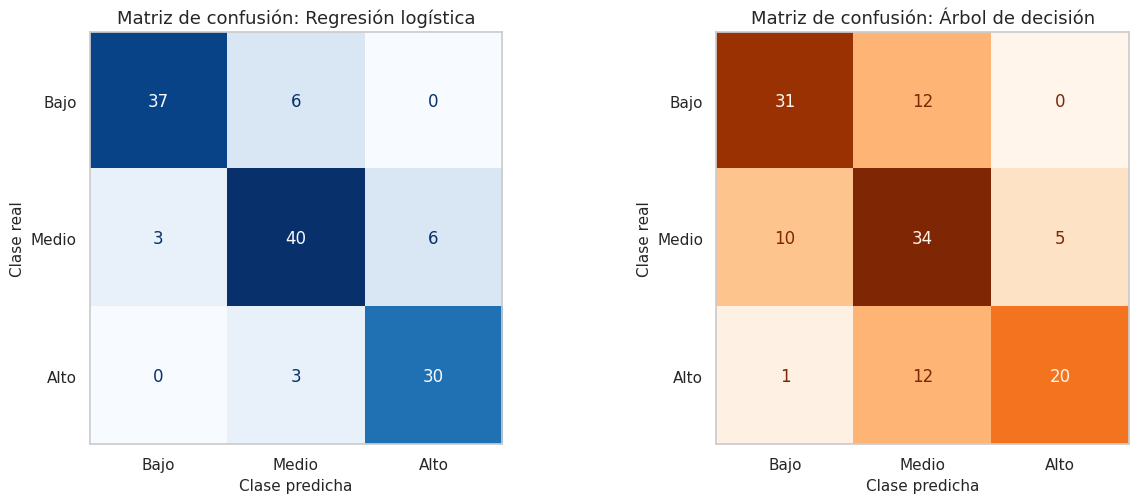

Regresión logística


,Pred. Bajo,Pred. Medio,Pred. Alto
Real Bajo,37,6,0
Real Medio,3,40,6
Real Alto,0,3,30


Árbol de decisión


,Pred. Bajo,Pred. Medio,Pred. Alto
Real Bajo,31,12,0
Real Medio,10,34,5
Real Alto,1,12,20


In [21]:
matrices = {n: confusion_matrix(y_test, p, labels=ORDEN) for n, (p, _) in resultados.items()}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (n, m), cmap in zip(axes, matrices.items(), ["Blues", "Oranges"]):
    ConfusionMatrixDisplay(m, display_labels=ORDEN).plot(cmap=cmap, values_format="d", ax=ax, colorbar=False)
    ax.set(title=f"Matriz de confusión: {n}", xlabel="Clase predicha", ylabel="Clase real"); ax.grid(False)
plt.tight_layout(); plt.show()
for n, m in matrices.items():
    print(n); display(pd.DataFrame(m, index=[f"Real {c}" for c in ORDEN], columns=[f"Pred. {c}" for c in ORDEN]))

**Interpretación de las matrices.** La regresión logística acierta 107 de 125 registros. Sus 18 errores son 6 Bajo→Medio, 3 Medio→Bajo, 6 Medio→Alto y 3 Alto→Medio, es decir, **todos entre clases vecinas** y ninguno entre Bajo y Alto. El árbol acierta 85 y comete 40 errores: 12 Bajo→Medio, 10 Medio→Bajo, 5 Medio→Alto, 12 Alto→Medio y 1 Alto→Bajo; 39 de ellos son entre clases vecinas. Los 12 pacientes de riesgo Alto clasificados como Medio (el 36.4 % de los 33 de esa clase) son el principal punto débil del árbol.

## 5.3 Análisis de errores, con énfasis en la clase Alto

In [22]:
filas = []
for n, m in matrices.items():
    total = m.sum(); correctos = np.trace(m)
    vecinos = m[0, 1] + m[1, 0] + m[1, 2] + m[2, 1]
    extremos = m[0, 2] + m[2, 0]
    alto_real = m[2].sum(); alto_detectado = m[2, 2]
    filas.append({"modelo": n, "aciertos": f"{correctos}/{total}", "errores totales": total - correctos,
                  "errores entre clases vecinas": vecinos, "errores Bajo<->Alto": extremos,
                  "Alto real clasificado como Medio": m[2, 1], "Alto real clasificado como Bajo": m[2, 0],
                  "Alto detectado (recall)": f"{alto_detectado}/{alto_real} = {alto_detectado / alto_real:.3f}",
                  "No-Alto predicho como Alto (falsas alarmas)": m[0, 2] + m[1, 2]})
errores = pd.DataFrame(filas).set_index("modelo").T
errores

modelo,Regresión logística,Árbol de decisión
aciertos,107/125,85/125
errores totales,18,40
errores entre clases vecinas,18,39
errores Bajo<->Alto,0,1
Alto real clasificado como Medio,3,12
Alto real clasificado como Bajo,0,1
Alto detectado (recall),30/33 = 0.909,20/33 = 0.606
No-Alto predicho como Alto (falsas alarmas),6,5


In [23]:
# Incertidumbre por el tamaño de la prueba: intervalos de Wilson al 95 %
def wilson(k, n):
    ci = stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return f"{k / n:.3f} [{ci.low:.3f}, {ci.high:.3f}]"

filas = []
for n, m in matrices.items():
    filas.append({"modelo": n, "Accuracy [IC 95 %]": wilson(np.trace(m), m.sum()),
                  "Recall Alto [IC 95 %]": wilson(m[2, 2], m[2].sum())})
pd.DataFrame(filas).set_index("modelo")

,Accuracy [IC 95 %],Recall Alto [IC 95 %]
modelo,,
Regresión logística,"0.856 [0.784, 0.907]","0.909 [0.764, 0.969]"
Árbol de decisión,"0.680 [0.594, 0.755]","0.606 [0.437, 0.753]"


**Intervalos de confianza.** Con solo 125 registros de prueba (33 de clase Alto) las estimaciones son imprecisas. Los intervalos de Wilson al 95 % del accuracy son [0.784, 0.907] para la logística y [0.594, 0.755] para el árbol, y no se solapan. Para el recall de Alto son [0.764, 0.969] y [0.437, 0.753]; en este caso el solapamiento es pequeño, por lo que la ventaja en recall de Alto es consistente con la de las demás métricas pero debe interpretarse con cautela.

**Interpretación.** El criterio de comparación no es solo el accuracy. Para un problema de riesgo, el error más costoso es que un paciente de riesgo **Alto** sea clasificado como Medio o Bajo (falso negativo de Alto), porque quedaría sin atención prioritaria; los falsos positivos de Alto son menos graves (se revisaría a alguien que no lo necesitaba). Por eso se examinan el recall de Alto y las confusiones extremas Bajo↔Alto. *(Esto es un criterio de evaluación del ejercicio, no un criterio clínico.)*

## 5.4 Validación cruzada y comparación entrenamiento–prueba
La validación cruzada (5 particiones estratificadas) se aplica **solo sobre el conjunto de entrenamiento** y aporta una estimación de estabilidad independiente de la partición única entrenamiento/prueba.

In [24]:
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "recall_Alto": make_scorer(recall_score, labels=["Alto"], average="macro", zero_division=0)}
filas = []
for n, fabrica in [("Regresión logística", crear_logistica), ("Árbol de decisión", lambda: crear_arbol(5))]:
    r = cross_validate(fabrica(), X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)
    modelo = resultados[n][1]
    filas.append({"Modelo": n,
                  "Accuracy CV": r["test_accuracy"].mean(), "Desv. Accuracy CV": r["test_accuracy"].std(),
                  "F1 macro CV": r["test_f1_macro"].mean(), "Desv. F1 CV": r["test_f1_macro"].std(),
                  "Recall Alto CV": r["test_recall_Alto"].mean(),
                  "Accuracy entrenamiento": modelo.score(X_train, y_train), "Accuracy prueba": modelo.score(X_test, y_test)})
validacion = pd.DataFrame(filas).set_index("Modelo").round(3)
validacion["Brecha entren.–prueba"] = (validacion["Accuracy entrenamiento"] - validacion["Accuracy prueba"]).round(3)
validacion

,Accuracy CV,Desv. Accuracy CV,F1 macro CV,Desv. F1 CV,Recall Alto CV,Accuracy entrenamiento,Accuracy prueba,Brecha entren.–prueba
Modelo,,,,,,,,
Regresión logística,0.844,0.045,0.849,0.045,0.929,0.871,0.856,0.015
Árbol de decisión,0.613,0.042,0.615,0.037,0.646,0.817,0.680,0.137


In [25]:
# Estabilidad por partición: F1 macro de cada pliegue
pliegues = pd.DataFrame({
    n: cross_validate(f(), X_train, y_train, cv=cv, scoring="f1_macro")["test_score"]
    for n, f in [("Regresión logística", crear_logistica), ("Árbol de decisión", lambda: crear_arbol(5))]
}, index=[f"Partición {i}" for i in range(1, 6)]).round(3)
pliegues["¿Logística supera al árbol?"] = pliegues["Regresión logística"] > pliegues["Árbol de decisión"]
pliegues

,Regresión logística,Árbol de decisión,¿Logística supera al árbol?
Partición 1,0.801,0.587,True
Partición 2,0.860,0.564,True
Partición 3,0.894,0.617,True
Partición 4,0.897,0.634,True
Partición 5,0.791,0.673,True


**Interpretación.** La regresión logística obtiene en validación cruzada un accuracy de 0.844 (± 0.045), un F1 macro de 0.849 (± 0.045) y un recall de Alto de 0.929; el árbol, 0.613 (± 0.042), 0.615 (± 0.037) y 0.646. La logística supera al árbol en las cinco particiones. La brecha entre entrenamiento y prueba es de 1.5 puntos de accuracy en la logística (0.871 frente a 0.856), compatible con buena generalización, y de 13.7 puntos en el árbol (0.817 frente a 0.680), compatible con sobreajuste. *Nota:* el F1 macro CV aquí se calcula solo con el conjunto de entrenamiento (372 registros), por lo que difiere del calculado sobre los 497 registros en el primer avance (0.837 y 0.640).

**Qué aporta:** el accuracy de prueba depende de una sola partición de 125 registros; la validación cruzada muestra si la diferencia entre modelos se sostiene en distintas particiones. También se compara entrenamiento con prueba para detectar sobreajuste (brecha).

## 5.5 Variables más relevantes
Se presentan tres lecturas complementarias: coeficientes de la regresión logística, importancia en el árbol e importancia por permutación en prueba (que mide cuánto empeora el F1 macro al desordenar cada variable). **Importancia ≠ causalidad.**

In [26]:
nombres = modelo_log.named_steps["preprocesamiento"].get_feature_names_out()
coef = pd.DataFrame(modelo_log.named_steps["modelo"].coef_, index=modelo_log.named_steps["modelo"].classes_, columns=nombres).T
coef = coef[["Bajo", "Medio", "Alto"]]
top = coef["Alto"].abs().sort_values(ascending=False).head(10).index
print("Coeficientes de la regresión logística (variables estandarizadas; positivo = aumenta la propensión a la clase):")
display(coef.loc[top].round(3))

imp_arbol = pd.Series(modelo_arb.named_steps["modelo"].feature_importances_, index=nombres).sort_values(ascending=False)
print("Importancia en el árbol de decisión (top 8):"); display(imp_arbol.head(8).round(3).to_frame("importancia"))

Coeficientes de la regresión logística (variables estandarizadas; positivo = aumenta la propensión a la clase):


,Bajo,Medio,Alto
num__Glucosa_mg_dL,-2.222,-0.203,2.426
cat__Actividad_Fisica_Baja,-1.598,-0.086,1.684
num__Edad,-1.771,0.293,1.478
num__Presion_Sistolica_mmHg,-1.075,-0.388,1.463
cat__Actividad_Fisica_Alta,1.337,0.075,-1.413
num__IMC,-1.302,0.146,1.156
cat__Fumador_No,1.165,-0.063,-1.102
cat__Fumador_Sí,-1.163,0.066,1.097
num__Horas_Sueno,0.642,0.207,-0.849
num__Colesterol_mg_dL,-0.606,-0.193,0.799


Importancia en el árbol de decisión (top 8):


,importancia
num__Glucosa_mg_dL,0.364
num__Edad,0.197
num__IMC,0.148
cat__Actividad_Fisica_Baja,0.098
num__Colesterol_mg_dL,0.065
num__Presion_Sistolica_mmHg,0.058
num__Mes_Numero,0.029
num__Consultas_Medicas,0.022


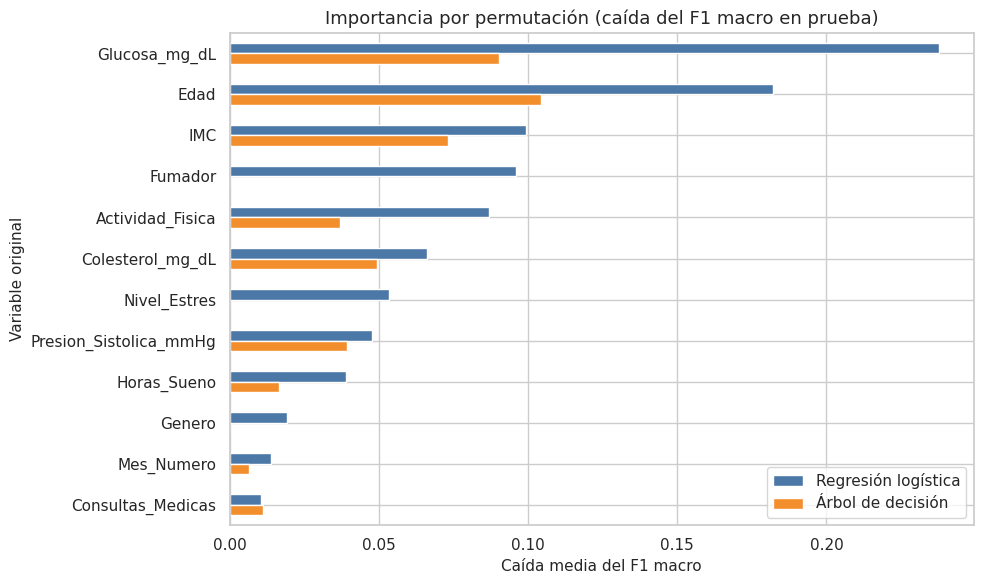

,Regresión logística,Árbol de decisión
Glucosa_mg_dL,0.238,0.090
Edad,0.182,0.104
IMC,0.099,0.073
Fumador,0.096,0.000
Actividad_Fisica,0.087,0.037
Colesterol_mg_dL,0.066,0.050
Nivel_Estres,0.054,0.000
Presion_Sistolica_mmHg,0.048,0.039
Horas_Sueno,0.039,0.017
Genero,0.019,0.000


In [27]:
pi = {}
for n, (_, m) in resultados.items():
    r = permutation_importance(m, X_test, y_test, scoring="f1_macro", n_repeats=30, random_state=SEMILLA)
    pi[n] = pd.Series(r.importances_mean, index=PREDICTORES)
pi = pd.DataFrame(pi).sort_values("Regresión logística", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
pi.plot(kind="barh", ax=ax, color=["#4C78A8", "#F28E2B"])
ax.invert_yaxis()
ax.set(title="Importancia por permutación (caída del F1 macro en prueba)", xlabel="Caída media del F1 macro", ylabel="Variable original")
plt.tight_layout(); plt.show()
pi.round(3)

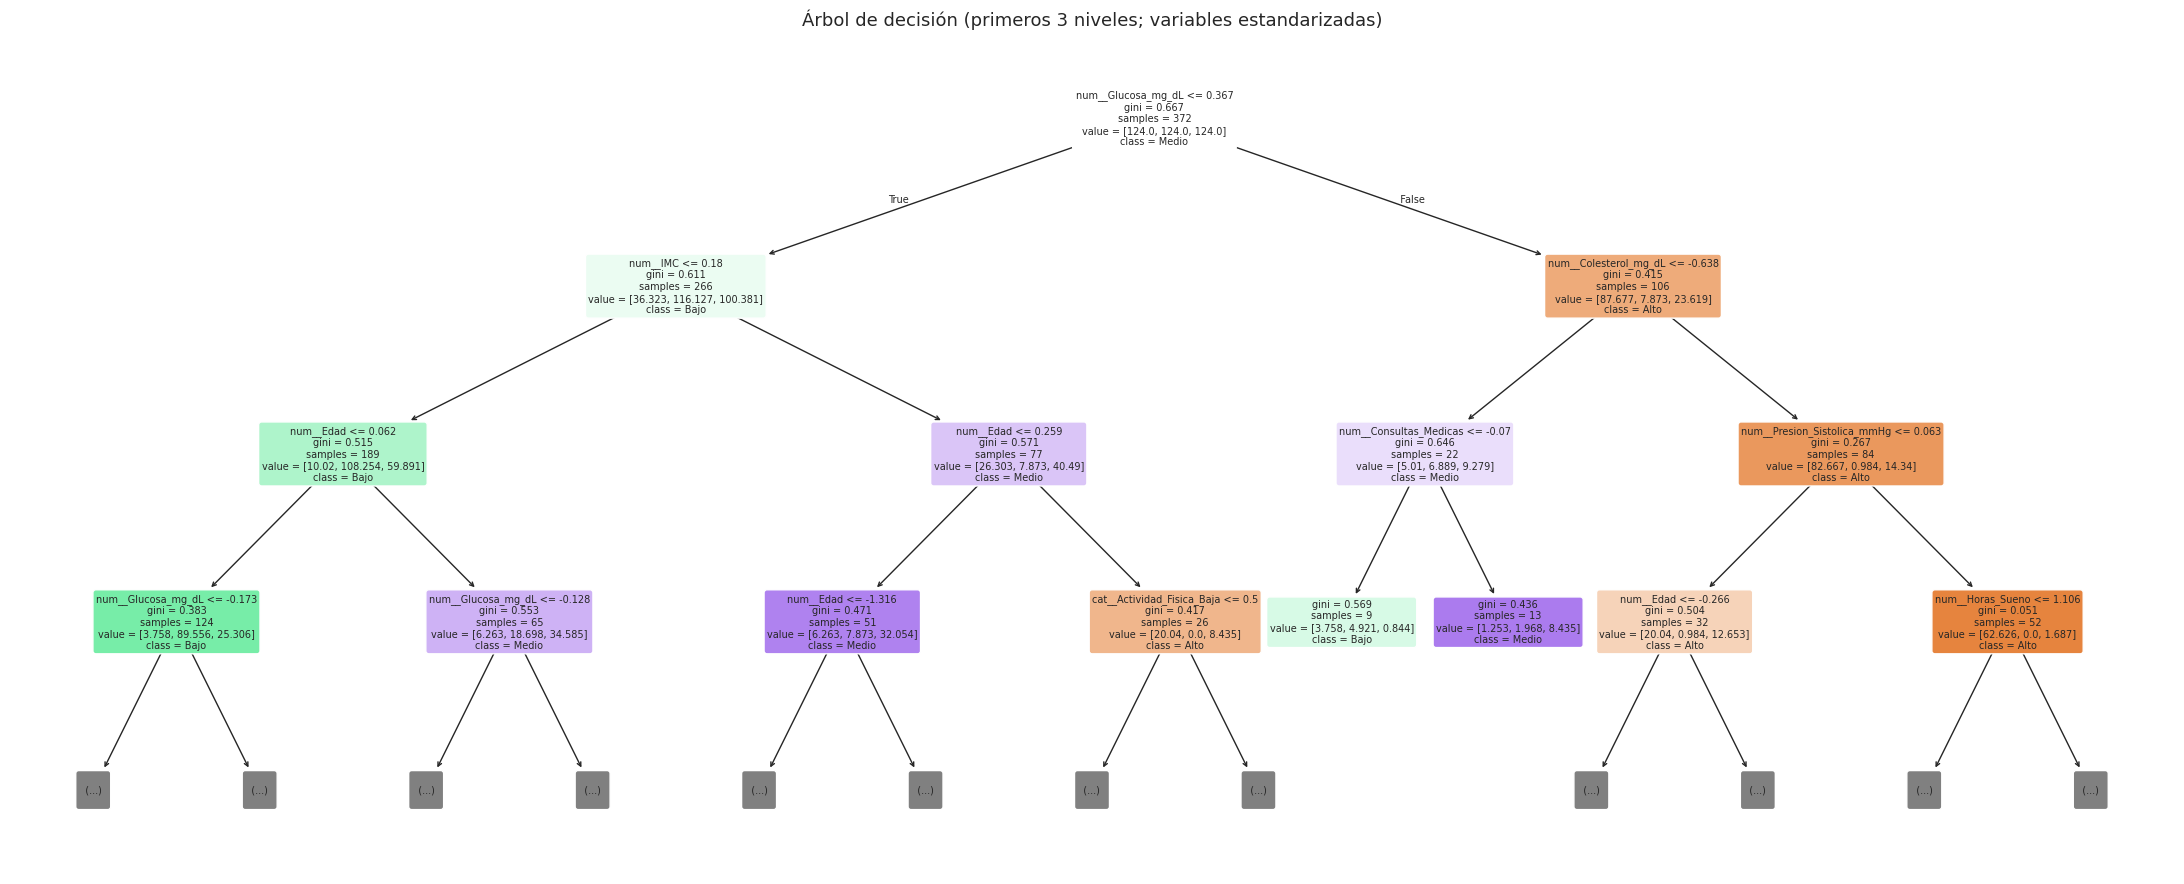

In [28]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(modelo_arb.named_steps["modelo"], feature_names=list(nombres), class_names=list(modelo_arb.named_steps["modelo"].classes_),
          filled=True, rounded=True, fontsize=7, max_depth=3, ax=ax)
ax.set_title("Árbol de decisión (primeros 3 niveles; variables estandarizadas)")
plt.tight_layout(); plt.show()

**Interpretación.** La **glucosa** es la variable más relevante en las tres lecturas: mayor coeficiente de la logística para Alto (+2.426) y para Bajo (−2.222), mayor importancia en el árbol (0.364) y mayor caída del F1 macro por permutación en la logística (0.238) y en el árbol (0.090). Le siguen la **edad** (coeficiente +1.478 para Alto; permutación 0.182 y 0.104), el **IMC**, la **actividad física** y la presión sistólica. Las lecturas no coinciden por completo: el hábito de fumar tiene un peso apreciable en la logística (permutación 0.096; coeficiente +1.097 para Alto) pero importancia 0 en el árbol, y lo mismo ocurre con el estrés (0.054 frente a 0). El árbol, a su vez, asigna alguna importancia al mes de registro (0.029), variable sin relevancia conceptual y con asociación débil en el EDA, lo que puede reflejar ajuste al ruido. Esto coincide con el EDA: glucosa, edad e IMC son las variables más asociadas con el riesgo. La importancia describe el comportamiento del modelo y no demuestra causalidad.

**Nota:** el árbol y los coeficientes están en la escala estandarizada, por lo que los umbrales no están en unidades originales. Para interpretarlos en unidades originales se debe revertir el escalamiento con la media y desviación del entrenamiento.

## 5.6 Verificación de continuidad: ¿coinciden los resultados con el primer avance?
Se comprueba que, con los mismos datos, partición, semilla y pipelines, se reproducen las métricas del informe anterior.

In [29]:
ref_primer_avance = {"Regresión logística": {"Accuracy": 0.856, "F1 macro": 0.859, "aciertos": 107},
                     "Árbol de decisión": {"Accuracy": 0.680, "F1 macro": 0.685, "aciertos": 85}}
comp = []
for n, (p, _) in resultados.items():
    comp.append({"modelo": n, "Accuracy (este avance)": round(accuracy_score(y_test, p), 3), "Accuracy (avance 1)": ref_primer_avance[n]["Accuracy"],
                 "F1 macro (este avance)": round(f1_score(y_test, p, average="macro"), 3), "F1 macro (avance 1)": ref_primer_avance[n]["F1 macro"],
                 "aciertos (este avance)": int((p == y_test).sum()), "aciertos (avance 1)": ref_primer_avance[n]["aciertos"]})
pd.DataFrame(comp).set_index("modelo")

,Accuracy (este avance),Accuracy (avance 1),F1 macro (este avance),F1 macro (avance 1),aciertos (este avance),aciertos (avance 1)
modelo,,,,,,
Regresión logística,0.856,0.856,0.859,0.859,107,107
Árbol de decisión,0.680,0.680,0.685,0.685,85,85


## 5.7 Sensibilidad frente a los valores atípicos (verificación de la decisión de conservarlos)
Se reentrena la regresión logística y el árbol excluyendo del **entrenamiento** los registros atípicos según IQR en glucosa, IMC y presión, y se evalúa sobre la **misma** prueba completa. Es solo un análisis de sensibilidad: el modelo principal sigue siendo el entrenado con todos los datos.

In [30]:
def mascara_atipicos(datos, columnas):
    m = pd.Series(False, index=datos.index)
    for c in columnas:
        q1, q3 = X_train[c].quantile([.25, .75]); iqr = q3 - q1
        m |= (datos[c] < q1 - 1.5 * iqr) | (datos[c] > q3 + 1.5 * iqr)
    return m

cols_at = ["Glucosa_mg_dL", "IMC", "Presion_Sistolica_mmHg"]
atip = mascara_atipicos(X_train, cols_at)
print(f"Atípicos en entrenamiento (glucosa, IMC o presión): {int(atip.sum())} de {len(X_train)}")
print("Su distribución por clase:", y_train[atip].value_counts().to_dict())

filas = []
for n, f in [("Regresión logística", crear_logistica), ("Árbol de decisión", lambda: crear_arbol(5))]:
    m_sin = f().fit(X_train[~atip], y_train[~atip]); p_sin = m_sin.predict(X_test)
    filas.append({"modelo": n, "Accuracy con todos": round(accuracy_score(y_test, resultados[n][0]), 3), "Accuracy sin atípicos": round(accuracy_score(y_test, p_sin), 3),
                  "F1 macro con todos": round(f1_score(y_test, resultados[n][0], average="macro"), 3), "F1 macro sin atípicos": round(f1_score(y_test, p_sin, average="macro"), 3)})
pd.DataFrame(filas).set_index("modelo")

Atípicos en entrenamiento (glucosa, IMC o presión): 10 de 372
Su distribución por clase: {'Alto': 10}


,Accuracy con todos,Accuracy sin atípicos,F1 macro con todos,F1 macro sin atípicos
modelo,,,,
Regresión logística,0.856,0.848,0.859,0.850
Árbol de decisión,0.680,0.648,0.685,0.654


**Interpretación.** Los 10 registros atípicos del entrenamiento pertenecen todos a la clase Alto. Al excluirlos, el accuracy baja de 0.856 a 0.848 en la logística y de 0.680 a 0.648 en el árbol, y el F1 macro baja de 0.859 a 0.850 y de 0.685 a 0.654. Quitarlos no mejora a ningún modelo (la pérdida es pequeña en la logística), lo que respalda **conservarlos** como se decidió en la sección 2.

# 6. Comparación técnica y discusión

In [31]:
resumen = pd.DataFrame({
    "Accuracy": globales["Accuracy"], "F1 macro": globales["F1 macro"],
    "F1 macro CV": validacion["F1 macro CV"],
    "Recall Alto": [recall_score(y_test, p, labels=["Alto"], average="macro") for p, _ in resultados.values()],
    "Precision Alto": [precision_score(y_test, p, labels=["Alto"], average="macro") for p, _ in resultados.values()],
    "Errores totales": [int((p != y_test).sum()) for p, _ in resultados.values()],
    "Errores Bajo<->Alto": [int(m[0, 2] + m[2, 0]) for m in matrices.values()],
    "Alto→Medio/Bajo": [int(m[2, 0] + m[2, 1]) for m in matrices.values()],
}).round(3)
resumen

,Accuracy,F1 macro,F1 macro CV,Recall Alto,Precision Alto,Errores totales,Errores Bajo<->Alto,Alto→Medio/Bajo
Regresión logística,0.856,0.859,0.849,0.909,0.833,18,0,3
Árbol de decisión,0.680,0.685,0.615,0.606,0.800,40,1,13


## 6.1 Discusión

**Modelo con mejores resultados.** La regresión logística resultó el modelo más adecuado. Las evidencias son: (i) accuracy de 0.856 frente a 0.680 y F1 macro de 0.859 frente a 0.685 en prueba, con intervalos de confianza del accuracy que no se solapan; (ii) F1 macro en validación cruzada de 0.849 frente a 0.615, con victoria en las cinco particiones; (iii) mejor recall en la clase Alto (0.909 frente a 0.606), con solo 3 pacientes Alto clasificados como Medio y ninguno como Bajo, frente a 12 y 1 en el árbol; (iv) todos sus errores son entre clases vecinas; y (v) una brecha entrenamiento–prueba de 1.5 puntos frente a 13.7 del árbol. El árbol solo tuvo 1 falsa alarma menos de Alto (5 frente a 6) y es más fácil de explicar mediante reglas, pero su rendimiento es claramente inferior.

**Variables más relevantes.** Glucosa, edad e IMC, seguidas de actividad física, presión sistólica y colesterol. Horas de sueño, género y mes de registro aportan poco. Son asociaciones sobre datos sintéticos y no relaciones causales.

**Principales errores.** Se concentran en la clase Medio y en las fronteras Bajo–Medio y Medio–Alto, como anticipaba el solapamiento observado en el EDA. El error más relevante, Alto clasificado como Medio, afecta sobre todo al árbol (12 casos) y en menor medida a la logística (3 casos).

**Por qué la logística supera al árbol.** El EDA mostró relaciones monótonas entre las variables clínicas y el riesgo, que la regresión logística modela de forma natural; un árbol poco profundo las aproxima con cortes y es más inestable con 372 registros de entrenamiento. Esta es una interpretación coherente con los resultados, no una comprobación (no se probaron modelos adicionales).

**Limitaciones.** (1) Los datos son sintéticos y la etiqueta fue construida a partir de variables del propio dataset, por lo que el rendimiento refleja en parte la recuperación de esa regla y no es generalizable a pacientes reales. (2) El conjunto de prueba es pequeño (125 registros, 33 de clase Alto) y los intervalos de confianza son amplios. (3) Se usó una sola partición de prueba y no se optimizaron hiperparámetros. (4) La categoría «Otro/No reporta» tiene 12 registros y no permite conclusiones. (5) El uso del resultado es solo educativo; no es un diagnóstico clínico.

**Posibles mejoras para el siguiente corte.** Optimizar hiperparámetros con validación cruzada (regularización de la logística y complejidad del árbol); probar modelos adicionales (por ejemplo, bosques aleatorios) solo si se justifican; repetir la validación cruzada con varias semillas; considerar un modelo ordinal, dado que el riesgo es ordenado; evaluar umbrales o costos asimétricos que penalicen más los falsos negativos de Alto; y prescindir de variables de baja relevancia como el mes.

# 7. Conclusiones

1. **Hallazgos del EDA.** Tras eliminar 3 duplicados quedan 497 registros con 25 celdas faltantes (≤ 1.4 % por variable). Las clases de `Nivel_Riesgo` son moderadamente desbalanceadas (Bajo 169, Medio 196, Alto 132). Glucosa, edad, IMC, presión sistólica y colesterol aumentan de forma ordenada con el riesgo (ρ de Spearman entre 0.43 y 0.61 con la escala Bajo–Medio–Alto), y la actividad física baja y el hábito de fumar se asocian con mayor proporción de riesgo Alto. Las clases se solapan, sobre todo la intermedia. Los valores atípicos extremos pertenecen principalmente a la clase Alto y se conservaron.
2. **Respuesta a la pregunta.** Sí es posible predecir `Nivel_Riesgo` con un desempeño razonable en este dataset sintético. La **regresión logística** fue el modelo más adecuado: accuracy de 0.856, F1 macro de 0.859 y recall de Alto de 0.909 en prueba, con F1 macro de 0.849 en validación cruzada. El árbol de decisión obtuvo 0.680, 0.685 y 0.606, y 0.615 en validación cruzada.
3. **Evidencias.** La selección se apoya en varias métricas, en los resultados por clase, en las matrices de confusión, en la validación cruzada (la logística superó al árbol en las 5 particiones) y en el tipo de errores, y no solo en el accuracy.
4. **Errores y limitaciones.** Los errores de la logística son 18, todos entre clases vecinas; los del árbol son 40, incluidos 12 registros de riesgo Alto clasificados como Medio. Los resultados están limitados por el carácter sintético de los datos, la construcción de la etiqueta a partir de las propias variables, el tamaño de la prueba y la ausencia de optimización de hiperparámetros. No constituyen recomendaciones clínicas.
5. **Aporte de cada etapa.** El EDA identificó las variables relevantes, el desbalance y el solapamiento entre clases, y orientó el uso de pesos de clase, de pipelines y de métricas por clase. El modelado confirmó esas señales y permitió comparar los modelos con criterios más allá del accuracy.

# 8. Reproducibilidad
- Semilla única `SEMILLA = 42` (partición, modelos, validación cruzada y permutación).
- Todas las transformaciones se ajustan dentro de pipelines, solo con el entrenamiento.
- Ruta relativa al dataset; las columnas usadas se verifican con `assert` en la sección 2.
- El notebook se ejecutó de principio a fin con las salidas conservadas.

9. Exportación del pipeline para Streamlit


In [32]:
import joblib

print("Accuracy prueba:", round(accuracy_score(y_test, pred_log), 3))   # esperado: 0.856
print("Clases del modelo:", modelo_log.classes_)

# Guardar pipeline completo y datos para la app
joblib.dump(modelo_log, "pipeline_riesgo.joblib")
df.to_csv("datos_limpios.csv", index=False)

prueba = X_test.copy()
prueba["Nivel_Riesgo"] = y_test.values
prueba.to_csv("datos_prueba.csv", index=False)
print("datos_prueba:", prueba.shape)   # esperado: (125, 13)

# Caso de referencia del conjunto de prueba
fila = X_test.iloc[[0]]
print(fila.T)
print("Predicción:", modelo_log.predict(fila)[0])
print("Probabilidades:", dict(zip(modelo_log.classes_, modelo_log.predict_proba(fila)[0].round(4))))
print("Real:", y_test.iloc[0])

Accuracy prueba: 0.856
Clases del modelo: ['Alto' 'Bajo' 'Medio']
datos_prueba: (125, 13)
                             314
Edad                          59
IMC                         23.5
Glucosa_mg_dL               97.0
Presion_Sistolica_mmHg       126
Colesterol_mg_dL           134.0
Horas_Sueno                  7.1
Nivel_Estres                   6
Consultas_Medicas              3
Mes_Numero                     7
Genero                  Femenino
Actividad_Fisica            Baja
Fumador                       Sí
Predicción: Medio
Probabilidades: {'Alto': np.float64(0.1268), 'Bajo': np.float64(0.0077), 'Medio': np.float64(0.8655)}
Real: Medio


In [33]:
import os, joblib
for f in ["pipeline_riesgo.joblib", "datos_limpios.csv", "datos_prueba.csv"]:
    print(f, "->", os.path.exists(f))

m = joblib.load("pipeline_riesgo.joblib")
print(m.classes_)

pipeline_riesgo.joblib -> True
datos_limpios.csv -> True
datos_prueba.csv -> True
['Alto' 'Bajo' 'Medio']


In [34]:
!pip install -q streamlit

import importlib.metadata as md
for p in ["streamlit", "scikit-learn", "pandas", "numpy"]:
    print(p, md.version(p))

streamlit 1.67.0
scikit-learn 1.6.1
pandas 2.2.3
numpy 2.4.6


In [35]:
%%writefile requirements.txt
streamlit
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
joblib
matplotlib
seaborn

Writing requirements.txt


In [40]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support

st.set_page_config(page_title="Riesgo de salud (prototipo académico)", page_icon="🩺", layout="wide")

ORDEN = ["Bajo", "Medio", "Alto"]
COLORES = {"Bajo": "#59A14F", "Medio": "#F2B134", "Alto": "#E15759"}
INTEGRANTES = ["Roberto Andrés Cortes Castillejo", "Roiner Luis Mejía Arrieta", "Santiago De Jesús Remolina López"]
NUMERICAS = ["Edad", "IMC", "Glucosa_mg_dL", "Presion_Sistolica_mmHg", "Colesterol_mg_dL",
             "Horas_Sueno", "Nivel_Estres", "Consultas_Medicas", "Mes_Numero"]
CATEGORICAS = ["Genero", "Actividad_Fisica", "Fumador"]
PREDICTORES = NUMERICAS + CATEGORICAS
CATEGORIAS = {"Genero": ["Femenino", "Masculino", "Otro/No reporta"],
              "Actividad_Fisica": ["Baja", "Moderada", "Alta"],
              "Fumador": ["No", "Sí"]}
ETIQUETAS = {"Edad": "Edad (años)", "IMC": "IMC (kg/m²)", "Glucosa_mg_dL": "Glucosa (mg/dL)",
             "Presion_Sistolica_mmHg": "Presión sistólica (mmHg)", "Colesterol_mg_dL": "Colesterol total (mg/dL)",
             "Horas_Sueno": "Horas de sueño por noche", "Nivel_Estres": "Nivel de estrés (1 a 10)",
             "Consultas_Medicas": "Consultas médicas en 12 meses", "Mes_Numero": "Mes de registro (1 a 12)",
             "Genero": "Género", "Actividad_Fisica": "Actividad física", "Fumador": "Fumador"}


@st.cache_resource
def cargar_modelo():
    return joblib.load("pipeline_riesgo.joblib")  # se carga, nunca se reentrena


@st.cache_data
def cargar_datos():
    return pd.read_csv("datos_limpios.csv"), pd.read_csv("datos_prueba.csv")


modelo = cargar_modelo()
datos, prueba = cargar_datos()
RANGOS = {c: (float(np.floor(datos[c].min())), float(np.ceil(datos[c].max()))) for c in NUMERICAS}


def validar(e):
    """Valida tipos, rangos (los vistos en el entrenamiento) y categorías."""
    errores = []
    for c in NUMERICAS:
        v = e[c]
        if v is None or not isinstance(v, (int, float, np.integer, np.floating)) or np.isnan(v):
            errores.append(f"{ETIQUETAS[c]}: debe ser un número.")
        elif not (RANGOS[c][0] <= v <= RANGOS[c][1]):
            errores.append(f"{ETIQUETAS[c]}: {v} está fuera del rango usado para entrenar el modelo "
                           f"({RANGOS[c][0]:g} a {RANGOS[c][1]:g}).")
    for c in CATEGORICAS:
        if e[c] not in CATEGORIAS[c]:
            errores.append(f"{ETIQUETAS[c]}: categoría no válida.")
    return errores


def predecir(fila_df):
    probs = modelo.predict_proba(fila_df)[0]
    por_clase = dict(zip(modelo.classes_, probs))  # classes_ está en orden alfabético
    return modelo.predict(fila_df)[0], por_clase


st.title("Clasificación del nivel de riesgo de salud")
st.warning("Prototipo académico con datos sintéticos. No es un diagnóstico y no sustituye una decisión profesional.")

tab1, tab2, tab3, tab4 = st.tabs(["Proyecto", "Exploración de datos", "Predicción", "Métricas y limitaciones"])

# ---------------- Proyecto ----------------
with tab1:
    st.header("Presentación del proyecto")
    st.markdown(
        "**Objetivo:** predecir el nivel de riesgo (Bajo, Medio o Alto) a partir de datos demográficos, "
        "mediciones clínicas simuladas y hábitos, con especial atención a los errores sobre la clase Alto.\n\n"
        "**Modelo:** regresión logística multinomial con preprocesamiento (imputación por mediana, "
        "estandarización y codificación one-hot) guardado como un único pipeline.\n\n"
        "**Fuente de los datos:** conjunto sintético generado con fines docentes "
        "(`Dataset_Sintetico_Salud_EDA.xlsx`, recurso de la asignatura Minería de Datos), 497 registros "
        "únicos de enero a diciembre de 2025.")
    st.subheader("Integrantes")
    for n in INTEGRANTES:
        st.write(f"- {n}")
    st.caption("Universidad de la Costa · Minería de Datos · Docente: José Escorcia Gutierrez")

# ---------------- EDA ----------------
with tab2:
    st.header("Visualizaciones del análisis exploratorio")
    c1, c2, c3 = st.columns(3)
    with c1:
        st.subheader("Distribución del riesgo")
        conteo = datos["Nivel_Riesgo"].value_counts().reindex(ORDEN)
        fig, ax = plt.subplots(figsize=(4, 3.4))
        ax.bar(ORDEN, conteo.values, color=[COLORES[o] for o in ORDEN])
        for i, v in enumerate(conteo.values):
            ax.text(i, v + 2, f"{v} ({v / conteo.sum():.1%})", ha="center", fontsize=8)
        ax.set(ylabel="Registros", xlabel="Nivel de riesgo")
        st.pyplot(fig)
    with c2:
        st.subheader("Glucosa según riesgo")
        fig, ax = plt.subplots(figsize=(4, 3.4))
        sns.boxplot(data=datos, x="Nivel_Riesgo", y="Glucosa_mg_dL", order=ORDEN, hue="Nivel_Riesgo", palette=COLORES, legend=False, ax=ax)
        ax.set(xlabel="Nivel de riesgo", ylabel="Glucosa (mg/dL)")
        st.pyplot(fig)
    with c3:
        st.subheader("Riesgo por actividad física")
        ct = pd.crosstab(datos["Actividad_Fisica"], datos["Nivel_Riesgo"]).reindex(CATEGORIAS["Actividad_Fisica"])[ORDEN]
        pct = ct.div(ct.sum(axis=1), axis=0) * 100
        fig, ax = plt.subplots(figsize=(4, 3.4))
        pct.plot(kind="bar", stacked=True, color=[COLORES[o] for o in ORDEN], ax=ax, rot=0)
        ax.set(xlabel="Actividad física", ylabel="% de registros", ylim=(0, 100))
        ax.legend(title="Riesgo", fontsize=7)
        st.pyplot(fig)
    st.caption("Las asociaciones describen los datos sintéticos y no implican causalidad.")

# ---------------- Predicción ----------------
with tab3:
    st.header("Consultar una predicción")
    with st.form("formulario"):
        a, b, c = st.columns(3)
        with a:
            edad = st.number_input(ETIQUETAS["Edad"], 0, 120, 45, 1)
            imc = st.number_input(ETIQUETAS["IMC"], 5.0, 100.0, 26.8, 0.1)
            glucosa = st.number_input(ETIQUETAS["Glucosa_mg_dL"], 20.0, 600.0, 103.0, 1.0)
            presion = st.number_input(ETIQUETAS["Presion_Sistolica_mmHg"], 50, 300, 122, 1)
        with b:
            colesterol = st.number_input(ETIQUETAS["Colesterol_mg_dL"], 50.0, 500.0, 190.0, 1.0)
            sueno = st.number_input(ETIQUETAS["Horas_Sueno"], 0.0, 24.0, 7.0, 0.1)
            estres = st.slider(ETIQUETAS["Nivel_Estres"], 1, 10, 5)
            consultas = st.number_input(ETIQUETAS["Consultas_Medicas"], 0, 50, 3, 1)
        with c:
            mes = st.selectbox(ETIQUETAS["Mes_Numero"], list(range(1, 13)), index=5)
            genero = st.selectbox(ETIQUETAS["Genero"], CATEGORIAS["Genero"])
            actividad = st.selectbox(ETIQUETAS["Actividad_Fisica"], CATEGORIAS["Actividad_Fisica"])
            fumador = st.selectbox(ETIQUETAS["Fumador"], CATEGORIAS["Fumador"])
        enviar = st.form_submit_button("Predecir")

    if enviar:
        entrada = {"Edad": edad, "IMC": imc, "Glucosa_mg_dL": glucosa, "Presion_Sistolica_mmHg": presion,
                   "Colesterol_mg_dL": colesterol, "Horas_Sueno": sueno, "Nivel_Estres": estres,
                   "Consultas_Medicas": consultas, "Mes_Numero": mes, "Genero": genero,
                   "Actividad_Fisica": actividad, "Fumador": fumador}
        errores = validar(entrada)
        if errores:
            for e in errores:
                st.error(e)
        else:
            clase, probs = predecir(pd.DataFrame([entrada])[PREDICTORES])
            st.success(f"Nivel de riesgo predicho: **{clase}** (probabilidad {probs[clase]:.2%})")
            st.bar_chart(pd.Series({o: probs[o] for o in ORDEN}, name="Probabilidad"))

    with st.expander("Verificar con un registro conocido del conjunto de prueba"):
        idx = st.number_input("Posición del registro (0 a %d)" % (len(prueba) - 1), 0, len(prueba) - 1, 0, 1)
        fila = prueba.iloc[[int(idx)]]
        st.dataframe(fila[PREDICTORES + ["Nivel_Riesgo"]], hide_index=True)
        clase, probs = predecir(fila[PREDICTORES])
        st.write(f"Predicción: **{clase}** · Real: **{fila['Nivel_Riesgo'].iloc[0]}** · "
                 + " · ".join(f"{o}: {probs[o]:.4f}" for o in ORDEN))

# ---------------- Métricas ----------------
with tab4:
    st.header("Métricas finales en el conjunto de prueba")
    y_real = prueba["Nivel_Riesgo"]
    y_pred = modelo.predict(prueba[PREDICTORES])
    p, r, f, s = precision_recall_fscore_support(y_real, y_pred, labels=ORDEN)
    m1, m2, m3 = st.columns(3)
    m1.metric("Accuracy", f"{accuracy_score(y_real, y_pred):.3f}")
    m2.metric("F1 macro", f"{f1_score(y_real, y_pred, average='macro'):.3f}")
    m3.metric("Recall de Alto", f"{r[2]:.3f}")
    st.dataframe(pd.DataFrame({"Clase": ORDEN, "Precision": p.round(3), "Recall": r.round(3),
                               "F1": f.round(3), "Registros": s}), hide_index=True)
    st.caption("Validación cruzada de 5 particiones sobre el entrenamiento (informe del Avance 2): "
               "accuracy 0.844 ± 0.045, F1 macro 0.849 ± 0.045.")
    st.subheader("Matriz de confusión")
    cm = confusion_matrix(y_real, y_pred, labels=ORDEN)
    fig, ax = plt.subplots(figsize=(4.5, 3.6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ORDEN, yticklabels=ORDEN, cbar=False, ax=ax)
    ax.set(xlabel="Clase predicha", ylabel="Clase real")
    st.pyplot(fig)
    st.header("Limitaciones")
    st.markdown(
        "- Los datos son **sintéticos** y la etiqueta se construyó a partir de otras variables del mismo conjunto, "
        "por lo que el rendimiento refleja en parte la recuperación de esa regla y no es generalizable.\n"
        "- La prueba es pequeña (125 registros, 33 de la clase Alto): el recall de Alto tiene un intervalo amplio.\n"
        "- Se usó una sola partición y no se optimizaron hiperparámetros.\n"
        "- La categoría «Otro/No reporta» tiene solo 12 registros.\n"
        "- Prototipo académico: no es un diagnóstico clínico.")

Overwriting app.py


In [39]:
!streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &>/content/logs.txt &
import time
time.sleep(5)
!./cloudflared tunnel --url http://localhost:8501

2026-11-12T01:17:07Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-12T01:17:07Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-12T01:17:11Z INF +--------------------------------------------------------------------------------------------+
2026-11-12T01:17:11Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-12T01:17:11Z INF |  https://unlock-chancellor-else-gets.trycloudflare.com

In [38]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared